# 4. Exploratory Data Analysis

Sebaran PM2.5 harian, ringkasan polutan dan pelampauan baku mutu, korelasi antarpolutan dan cuaca, rasio ragam terhadap rerata data kesehatan, dan hubungan awal PM2.5 dengan rawat inap ISPA balita per rumah sakit.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import pandas as pd
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
%matplotlib inline

## Sebaran PM2.5 harian

In [2]:
import numpy as np
import pandas as pd
from scipy.stats import skew, spearmanr

h = pd.read_csv("../data/mart/fakta_udara_harian.csv")
v = h[h["hari_valid"]]
p = v["pm25"]
print("Hari-stasiun valid:", len(p), "| stasiun:", v["stasiun"].nunique())
print("PM2.5 harian  rata-rata", round(p.mean(), 1), "| median", round(p.median(), 1),
      "| p95", round(p.quantile(0.95), 1), "| maks", round(p.max(), 1))
print("Kemiringan", round(skew(p), 2), "| kemiringan setelah log", round(skew(np.log(p)), 2))
print("Hari > 55 µg/m³:", (p > 55).sum(), f"({(p > 55).mean() * 100:.1f}%)",
      "| hari > 15 µg/m³ (WHO):", f"{(p > 15).mean() * 100:.1f}%")

Hari-stasiun valid: 24283 | stasiun: 25
PM2.5 harian  rata-rata 40.1 | median 31.1 | p95 97.3 | maks 1127.6
Kemiringan 9.56 | kemiringan setelah log 0.34
Hari > 55 µg/m³: 4128 (17.0%) | hari > 15 µg/m³ (WHO): 83.1%


## Ringkasan polutan dan pelampauan baku mutu

Baku mutu PP 22/2021: PM2.5 55 (24 jam), PM10 75 (24 jam), SO₂ 75 (24 jam) dan 150 (1 jam), NO₂ 65 (24 jam) dan 200 (1 jam), CO 4.000 (8 jam) dan 10.000 (1 jam), O₃ 100 (8 jam) dan 150 (1 jam).

In [3]:
ringkas = []
for nama, kol in [("PM2.5", "pm25"), ("PM10", "pm10"), ("SO2", "so2"), ("NO2", "no2"), ("CO", "co"), ("O3", "o3")]:
    x = v[kol].dropna()
    ringkas.append({"parameter": nama, "median": round(x.median(), 1), "persentil_95": round(x.quantile(0.95), 1),
                    "maksimum": round(x.max(), 1)})
ringkas = pd.DataFrame(ringkas)
lewat = {
    "PM2.5": (v["pm25"] > 55).sum(),
    "PM10": (v["pm10"] > 75).sum(),
    "SO2": ((v["so2"] > 75) | (v["so2_maks_1j"] > 150)).sum(),
    "NO2": ((v["no2"] > 65) | (v["no2_maks_1j"] > 200)).sum(),
    "CO": ((v["co_maks_8j"] > 4000) | (v["co_maks_1j"] > 10000)).sum(),
    "O3": ((v["o3_maks_8j"] > 100) | (v["o3_maks_1j"] > 150)).sum(),
}
ringkas["hari_lewat_baku_mutu"] = ringkas["parameter"].map(lewat)
ringkas["persen_hari"] = (ringkas["hari_lewat_baku_mutu"] / len(v) * 100).round(1)
ringkas

,parameter,median,persentil_95,maksimum,hari_lewat_baku_mutu,persen_hari
0,PM2.5,31.1,97.3,1127.6,4128,17.0
1,PM10,45.9,136.3,1391.0,5776,23.8
2,SO2,7.3,22.7,34.0,0,0.0
3,NO2,20.2,60.5,66.6,12,0.0
4,CO,431.3,1790.5,7594.1,28,0.1
5,O3,13.9,36.3,41.5,0,0.0


In [4]:
print("Stasiun dengan NO2 harian di atas 65 µg/m³:", v.loc[v["no2"] > 65, "stasiun"].unique().tolist())

Stasiun dengan NO2 harian di atas 65 µg/m³: ['JKT-02']


## Korelasi antarpolutan dan cuaca

Rata-rata matriks korelasi Spearman per stasiun pada data per jam (MER-01 tidak diikutkan karena datanya terlalu sedikit).

In [5]:
a = pd.read_csv("../data/clean/air_hourly_clean.csv",
                usecols=["stasiun", "pm25", "pm10", "so2", "co", "o3", "no2", "temperature_c", "humidity_pct", "wind_speed_ms"])
kolom = ["pm25", "pm10", "no2", "so2", "co", "o3", "temperature_c", "humidity_pct", "wind_speed_ms"]
matriks = [g[kolom].corr(method="spearman") for s, g in a.groupby("stasiun") if s != "MER-01"]
korelasi = sum(matriks) / len(matriks)
korelasi.round(2)

,pm25,pm10,no2,so2,co,o3,temperature_c,humidity_pct,wind_speed_ms
pm25,1.00,0.99,0.23,0.07,0.20,-0.09,-0.06,0.00,0.07
pm10,0.99,1.00,0.23,0.07,0.20,-0.09,-0.06,0.00,0.07
no2,0.23,0.23,1.00,0.01,0.18,-0.08,-0.10,-0.02,0.02
so2,0.07,0.07,0.01,1.00,0.02,0.01,0.05,-0.06,0.17
co,0.20,0.20,0.18,0.02,1.00,-0.04,0.01,-0.01,0.02
o3,-0.09,-0.09,-0.08,0.01,-0.04,1.00,0.41,-0.41,-0.16
temperature_c,-0.06,-0.06,-0.10,0.05,0.01,0.41,1.00,-0.80,-0.31
humidity_pct,0.00,0.00,-0.02,-0.06,-0.01,-0.41,-0.80,1.00,0.33
wind_speed_ms,0.07,0.07,0.02,0.17,0.02,-0.16,-0.31,0.33,1.00


## Sifat data kesehatan

In [6]:
s = pd.read_csv("../data/mart/fakta_kesehatan_harian.csv")
s = s[s["dipakai_analisis_dampak"]]
kasus = ["resp_admissions_under5", "resp_admissions_over60", "asthma_emergency_cases", "copd_admissions", "cvd", "death", "resp"]
dispersi = pd.DataFrame({
    "gabungan_semua_RS": (s[kasus].var() / s[kasus].mean()).round(2),
    "median_di_dalam_RS": s.groupby("hospital_id")[kasus].agg(lambda x: x.var() / x.mean()).median().round(2),
    "persen_hari_nol": (s[kasus] == 0).mean().mul(100).round(1),
})
dispersi

,gabungan_semua_RS,median_di_dalam_RS,persen_hari_nol
resp_admissions_under5,4.15,1.01,0.1
resp_admissions_over60,4.63,1.07,0.0
asthma_emergency_cases,2.98,1.04,2.5
copd_admissions,2.45,0.83,3.4
cvd,1.87,0.45,0.0
death,1.21,0.40,7.6
resp,11.17,1.59,0.0


## Hubungan awal PM2.5 dan ISPA balita per rumah sakit

In [7]:
per_rs = []
for hid, g in s.dropna(subset=["pm25"]).groupby("hospital_id"):
    per_rs.append({"hospital_id": hid, "stasiun": g["stasiun"].iloc[0], "sd_pm25": g["pm25"].std(),
                   "rho_ispa_balita": spearmanr(g["pm25"], g["resp_admissions_under5"])[0]})
per_rs = pd.DataFrame(per_rs).sort_values("rho_ispa_balita").round(2)
besar = per_rs[per_rs["sd_pm25"] >= 5]
kecil = per_rs[per_rs["sd_pm25"] < 5]
print("RS dengan sd PM2.5 >= 5:", len(besar), "| rho >= 0,35:", (besar["rho_ispa_balita"] >= 0.35).sum(),
      "| rentang", besar["rho_ispa_balita"].min(), "sampai", besar["rho_ispa_balita"].max())
print("RS dengan sd PM2.5 < 5:", len(kecil), "| rentang", kecil["rho_ispa_balita"].min(), "sampai", kecil["rho_ispa_balita"].max())
per_rs

RS dengan sd PM2.5 >= 5: 17 | rho >= 0,35: 16 | rentang -0.17 sampai 0.89
RS dengan sd PM2.5 < 5: 8 | rentang -0.03 sampai 0.1


,hospital_id,stasiun,sd_pm25,rho_ispa_balita
22,RS-XXX-24,MDN-01,6.10,-0.17
5,RS-XXX-06,BGR-01,0.37,-0.03
14,RS-XXX-15,SRG-01,4.05,-0.01
1,RS-XXX-02,JKT-02,2.97,0.00
17,RS-XXX-18,PLU-01,2.46,0.02
6,RS-XXX-07,BGR-02,0.37,0.05
0,RS-XXX-01,JKT-01,2.92,0.05
2,RS-XXX-03,JKT-03,2.95,0.08
8,RS-XXX-09,IDP-01,1.31,0.10
23,RS-XXX-25,SM2-01,64.50,0.35


## Gambar EDA

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

MART = "../data/mart/"
GAMBAR = "../hasil/gambar/"

h = pd.read_csv(MART + "fakta_udara_harian.csv")
v = h[h["hari_valid"]]
p = v["pm25"]

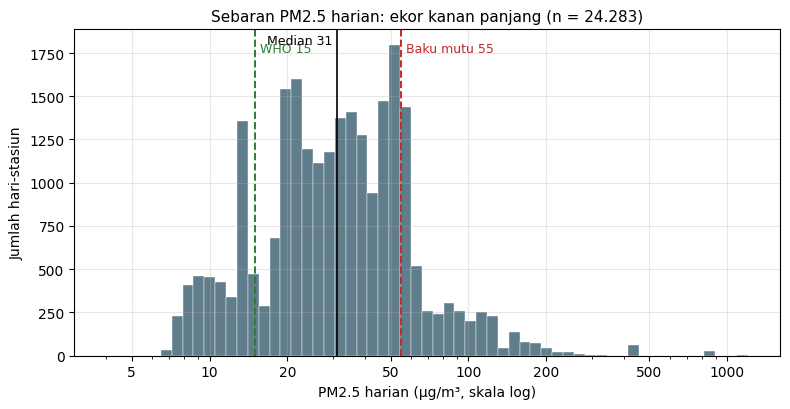

In [9]:
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.hist(p, bins=np.logspace(np.log10(4), np.log10(1200), 60), color="#607d8b", edgecolor="white", linewidth=0.3)
ax.set_xscale("log")
ax.set_xticks([5, 10, 20, 50, 100, 200, 500, 1000])
ax.set_xticklabels([5, 10, 20, 50, 100, 200, 500, 1000])
for x, lbl, c in [(15, "WHO 15", "#2e7d32"), (55, "Baku mutu 55", "#c62828")]:
    ax.axvline(x, color=c, ls="--", lw=1.4)
    ax.text(x * 1.04, ax.get_ylim()[1] * 0.93, lbl, color=c, fontsize=9)
ax.axvline(p.median(), color="black", lw=1.2)
ax.text(p.median() * 0.96, ax.get_ylim()[1] * 0.985, f"Median {p.median():.0f}", fontsize=9, ha="right", va="top")
ax.set_xlabel("PM2.5 harian (µg/m³, skala log)")
ax.set_ylabel("Jumlah hari-stasiun")
ax.set_title(f"Sebaran PM2.5 harian: ekor kanan panjang (n = {len(p):,}".replace(",", ".") + ")", fontsize=11)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(GAMBAR + "08_EDA_sebaran_pm25.png", dpi=170)
plt.show()

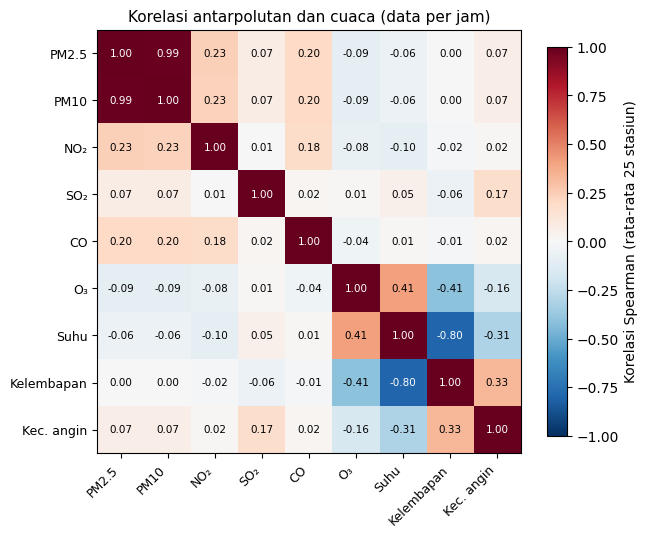

In [10]:
a = pd.read_csv("../data/clean/air_hourly_clean.csv",
                usecols=["stasiun", "pm25", "pm10", "no2", "so2", "co", "o3", "temperature_c", "humidity_pct", "wind_speed_ms"])
kol = ["pm25", "pm10", "no2", "so2", "co", "o3", "temperature_c", "humidity_pct", "wind_speed_ms"]
nama = ["PM2.5", "PM10", "NO₂", "SO₂", "CO", "O₃", "Suhu", "Kelembapan", "Kec. angin"]
ms = [g[kol].corr(method="spearman") for s, g in a.groupby("stasiun") if s != "MER-01"]
m = sum(ms) / len(ms)
fig, ax = plt.subplots(figsize=(6.6, 5.6))
im = ax.imshow(m.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(9))
ax.set_xticklabels(nama, rotation=45, ha="right", fontsize=9)
ax.set_yticks(range(9))
ax.set_yticklabels(nama, fontsize=9)
for i in range(9):
    for j in range(9):
        ax.text(j, i, f"{m.values[i, j]:.2f}", ha="center", va="center", fontsize=7.5,
                color="white" if abs(m.values[i, j]) > 0.6 else "black")
plt.colorbar(im, ax=ax, label="Korelasi Spearman (rata-rata 25 stasiun)", shrink=0.85)
ax.set_title("Korelasi antarpolutan dan cuaca (data per jam)", fontsize=11)
plt.tight_layout()
plt.savefig(GAMBAR + "08_EDA_korelasi_polutan_cuaca.png", dpi=170)
plt.show()

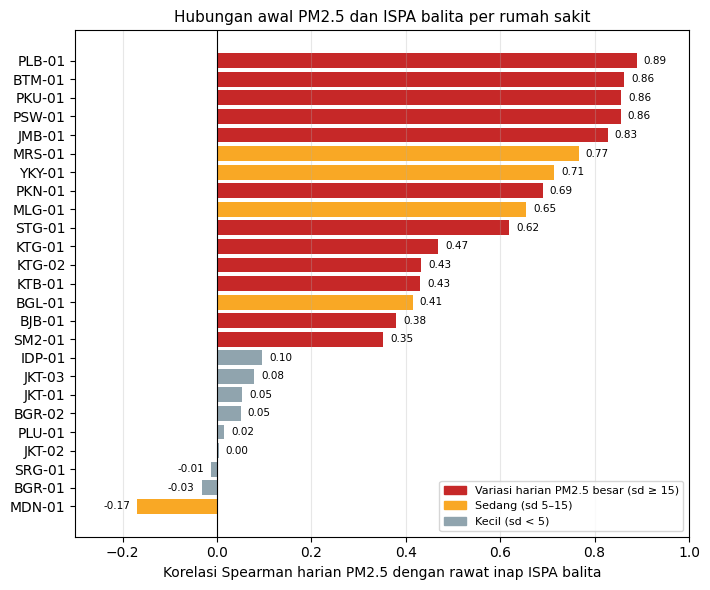

selesai


In [11]:
s = pd.read_csv(MART + "fakta_kesehatan_harian.csv")
s = s[s["dipakai_analisis_dampak"]].dropna(subset=["pm25"])
r = []
for hid, g in s.groupby("hospital_id"):
    r.append({"stasiun": g["stasiun"].iloc[0], "sd": g["pm25"].std(), "rho": spearmanr(g["pm25"], g["resp_admissions_under5"])[0]})
r = pd.DataFrame(r).sort_values("rho")
warna = ["#c62828" if x >= 15 else "#f9a825" if x >= 5 else "#90a4ae" for x in r["sd"]]
fig, ax = plt.subplots(figsize=(7.2, 6))
ax.barh(r["stasiun"], r["rho"], color=warna)
for y, (rho, sd) in enumerate(zip(r["rho"], r["sd"])):
    ax.text(rho + (0.015 if rho >= 0 else -0.015), y, f"{rho:.2f}", va="center", ha="left" if rho >= 0 else "right", fontsize=7.5)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlim(-0.3, 1.0)
ax.set_xlabel("Korelasi Spearman harian PM2.5 dengan rawat inap ISPA balita")
ax.set_title("Hubungan awal PM2.5 dan ISPA balita per rumah sakit", fontsize=11)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in ["#c62828", "#f9a825", "#90a4ae"]],
          labels=["Variasi harian PM2.5 besar (sd ≥ 15)", "Sedang (sd 5–15)", "Kecil (sd < 5)"], fontsize=8, loc="lower right")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig(GAMBAR + "08_EDA_korelasi_pm25_ispa_per_rs.png", dpi=170)
plt.show()
print("selesai")